# Assignment 1a: Nearest-Neighbor Image Resizing

This notebook saves its resized results under `output/part1a_resizing/`.

In [1]:
%matplotlib inline

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

image_path = Path("assignment-1-data/goldfish.jpg")
output_dir = Path("output/part1a_resizing")
if not image_path.is_file():
    raise FileNotFoundError(f"Could not find {image_path}. Run this notebook from the assignment folder.")

bgr_image = cv2.imread(str(image_path))
image = cv2.cvtColor(bgr_image, cv2.COLOR_BGR2RGB)

height, width = image.shape[:2]
print(f"Original image: {width} x {height} pixels")

Original image: 1250 x 905 pixels


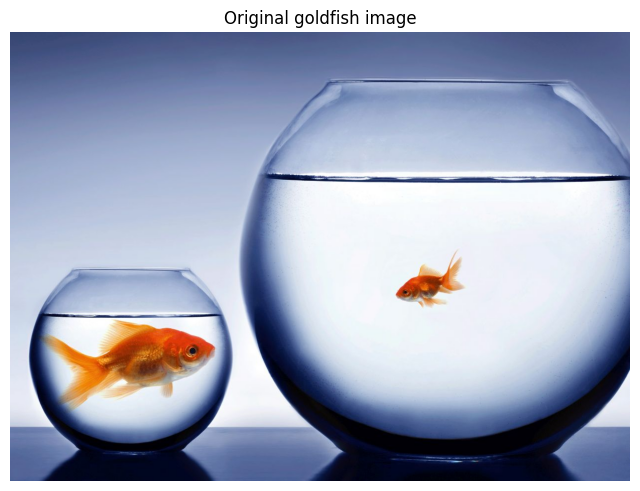

In [2]:
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.title('Original goldfish image')
plt.axis('off')
plt.show()

## Nearest-neighbor interpolation

For each output pixel, map its center to the input image and select the nearest input pixel. The source coordinate for horizontal output position `x` is `(x + 0.5) * source_width / output_width - 0.5`; the same mapping is used vertically. Clipping keeps the selected coordinate inside the input image.

In [3]:
def nn_resize(image, w, h):
    """Resize a grayscale or channel-last image with nearest neighbors."""
    image = np.asarray(image)
    if image.ndim not in (2, 3):
        raise ValueError('image must be a 2D grayscale or 3D channel-last array')
    if image.shape[0] == 0 or image.shape[1] == 0:
        raise ValueError('input image dimensions must be nonzero')
    if not isinstance(w, (int, np.integer)) or not isinstance(h, (int, np.integer)):
        raise TypeError('w and h must be integers')
    if w <= 0 or h <= 0:
        raise ValueError('w and h must be positive')

    source_height, source_width = image.shape[:2]
    output_shape = (h, w) + image.shape[2:]
    resized = np.empty(output_shape, dtype=image.dtype)

    for y_new in range(h):
        y_source_center = (y_new + 0.5) * source_height / h - 0.5
        y_old = int(np.floor(y_source_center + 0.5))
        y_old = min(max(y_old, 0), source_height - 1)
        for x_new in range(w):
            x_source_center = (x_new + 0.5) * source_width / w - 0.5
            x_old = int(np.floor(x_source_center + 0.5))
            x_old = min(max(x_old, 0), source_width - 1)
            resized[y_new, x_new] = image[y_old, x_old]

    return resized

In [4]:
up_width, up_height = round(width * 1.5), round(height * 1.5)
down_width, down_height = round(width * 0.5), round(height * 0.5)

resized_up = nn_resize(image, up_width, up_height)
resized_down = nn_resize(image, down_width, down_height)

print(f'Upscaled image: {up_width} x {up_height} pixels')
print(f'Downscaled image: {down_width} x {down_height} pixels')

Upscaled image: 1875 x 1358 pixels
Downscaled image: 625 x 452 pixels


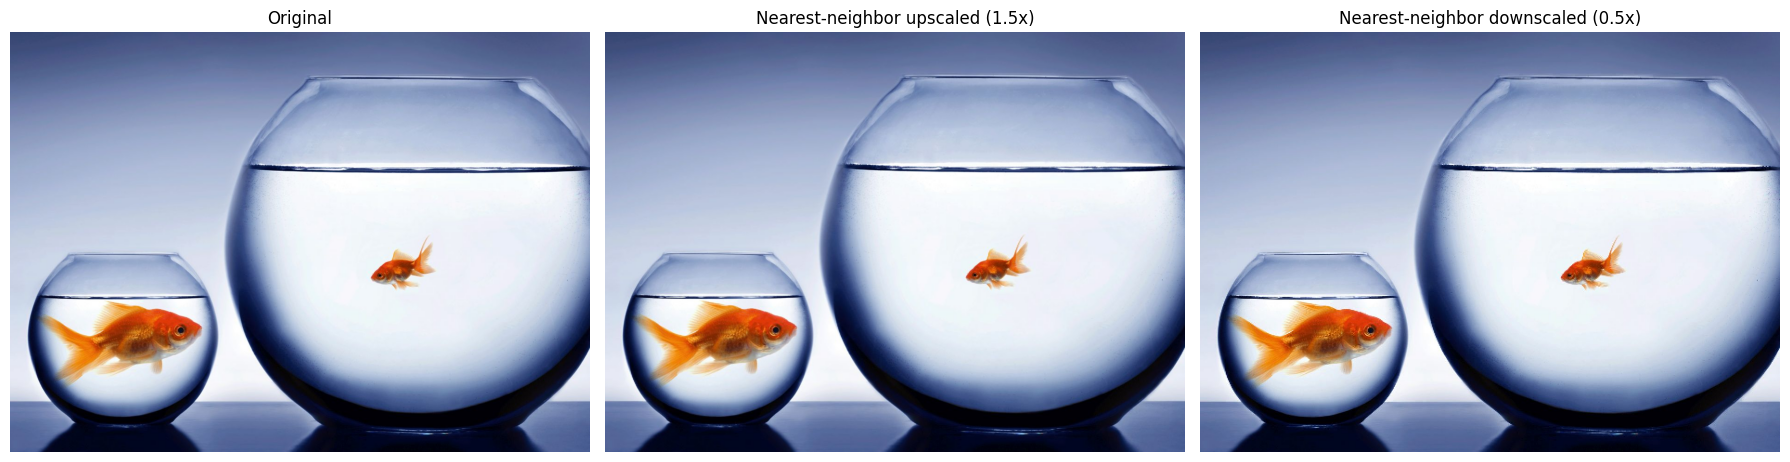

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for axis, pixels, title in zip(
    axes,
    (image, resized_up, resized_down),
    ('Original', 'Nearest-neighbor upscaled (1.5x)', 'Nearest-neighbor downscaled (0.5x)'),
):
    axis.imshow(pixels)
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()
plt.show()

In [6]:
output_dir.mkdir(parents=True, exist_ok=True)
cv2.imwrite(str(output_dir / "goldfish_nn_upscaled_1_5x.png"), cv2.cvtColor(resized_up, cv2.COLOR_RGB2BGR))
cv2.imwrite(str(output_dir / "goldfish_nn_downscaled_0_5x.png"), cv2.cvtColor(resized_down, cv2.COLOR_RGB2BGR))
print(f"Saved the resized images in {output_dir}")

Saved the resized images in output/part1a_resizing


### Part 1a observations

- Upscaling makes the image larger by repeating source pixel values. It does not add detail, and edges look blockier when inspected closely.
- Downscaling keeps fewer source samples, so small details may disappear and thin edges may look jagged. This implementation does not prefilter the image before reducing it.
- Nearest-neighbor interpolation is simple and preserves exact input colors, but it is less smooth than interpolation methods that blend neighboring pixels.